# Assignment 2: End-to-End Regression Project
## Medical Insurance Cost Prediction — From Raw Data to a Reusable Model

**Goal:** predict the yearly medical insurance `charges` of a person from `age`, `sex`, `bmi`, `children`, `smoker` and `region`.

**Pipeline:** explore the data → engineer features → build 3 regression models → evaluate them fairly → pick and interpret the best one → save it and reuse it for new predictions.

**How to run in Google Colab:** `Runtime → Run all`. When the upload widget appears in Section 1, choose `insurance.csv`. The saved model `insurance_model.joblib` appears in the Colab file panel (and is also auto-downloaded by the last cell).

---
# 1. Data Loading & Exploration
First the basics: size of the data, column types, missing values and duplicates, then a look at the target variable `charges` and how it relates to the main features.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42          # one seed used everywhere -> fair, reproducible comparisons
print("Libraries loaded.")

Libraries loaded.


In [2]:
# Upload insurance.csv with the Colab widget (falls back to a local file when not running in Colab)
try:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(next(iter(uploaded)))
except ImportError:
    df = pd.read_csv("insurance.csv")

print("Loaded:", df.shape)

Saving insurance.csv to insurance.csv
Loaded: (1338, 7)


In [3]:
print("Shape (rows, columns):", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nFirst 5 rows:")
df.head()

Shape (rows, columns): (1338, 7)

Column types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

First 5 rows:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
print("Missing values per column:")
print(df.isnull().sum())

n_dup = df.duplicated().sum()
print("\nDuplicate rows:", n_dup)
if n_dup:
    print(df[df.duplicated(keep=False)])
    df = df.drop_duplicates().reset_index(drop=True)
    print("\nDuplicate removed. New shape:", df.shape)

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1
     age   sex    bmi  children smoker     region    charges
195   19  male  30.59         0     no  northwest  1639.5631
581   19  male  30.59         0     no  northwest  1639.5631

Duplicate removed. New shape: (1337, 7)


In [5]:
print("Numeric summary statistics:")
display(df.describe().round(2))

print("\nCategorical value counts:")
for col in ["sex", "smoker", "region", "children"]:
    print(f"\n{col}:")
    print(df[col].value_counts())

Numeric summary statistics:


,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43



Categorical value counts:

sex:
sex
male      675
female    662
Name: count, dtype: int64

smoker:
smoker
no     1063
yes     274
Name: count, dtype: int64

region:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

children:
children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64


Skewness of charges:      1.515
Skewness of log(charges): -0.090


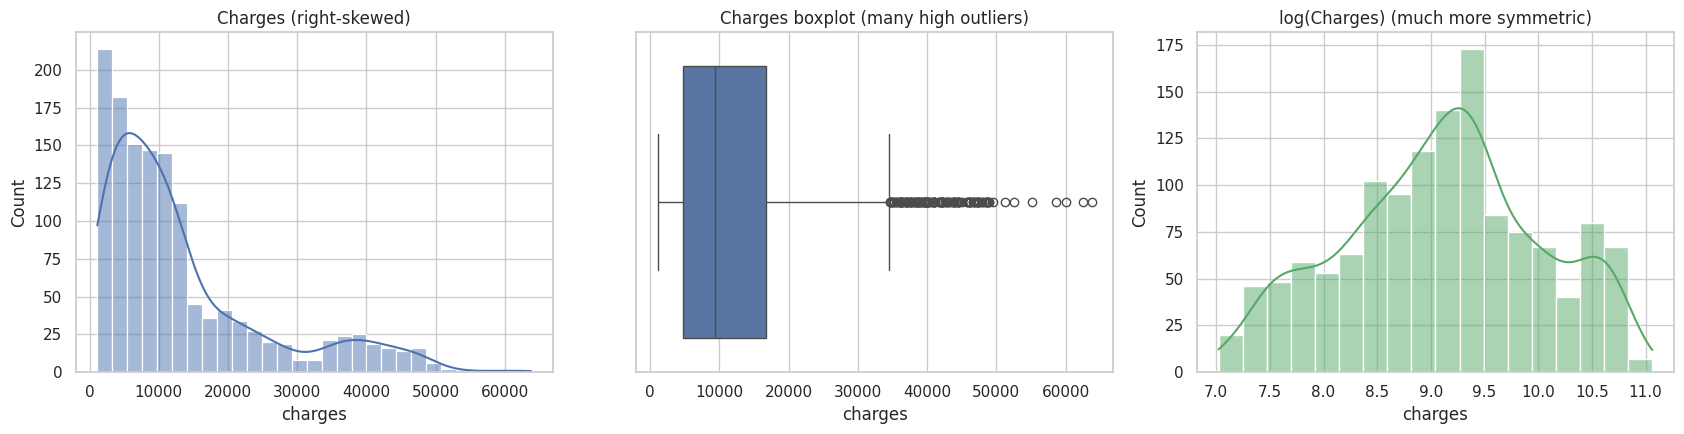

In [6]:
print(f"Skewness of charges:      {df['charges'].skew():.3f}")
print(f"Skewness of log(charges): {np.log(df['charges']).skew():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df["charges"], kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Charges (right-skewed)")
sns.boxplot(x=df["charges"], ax=axes[1], color="#4C72B0")
axes[1].set_title("Charges boxplot (many high outliers)")
sns.histplot(np.log(df["charges"]), kde=True, ax=axes[2], color="#55A868")
axes[2].set_title("log(Charges) (much more symmetric)")
plt.tight_layout()
plt.show()

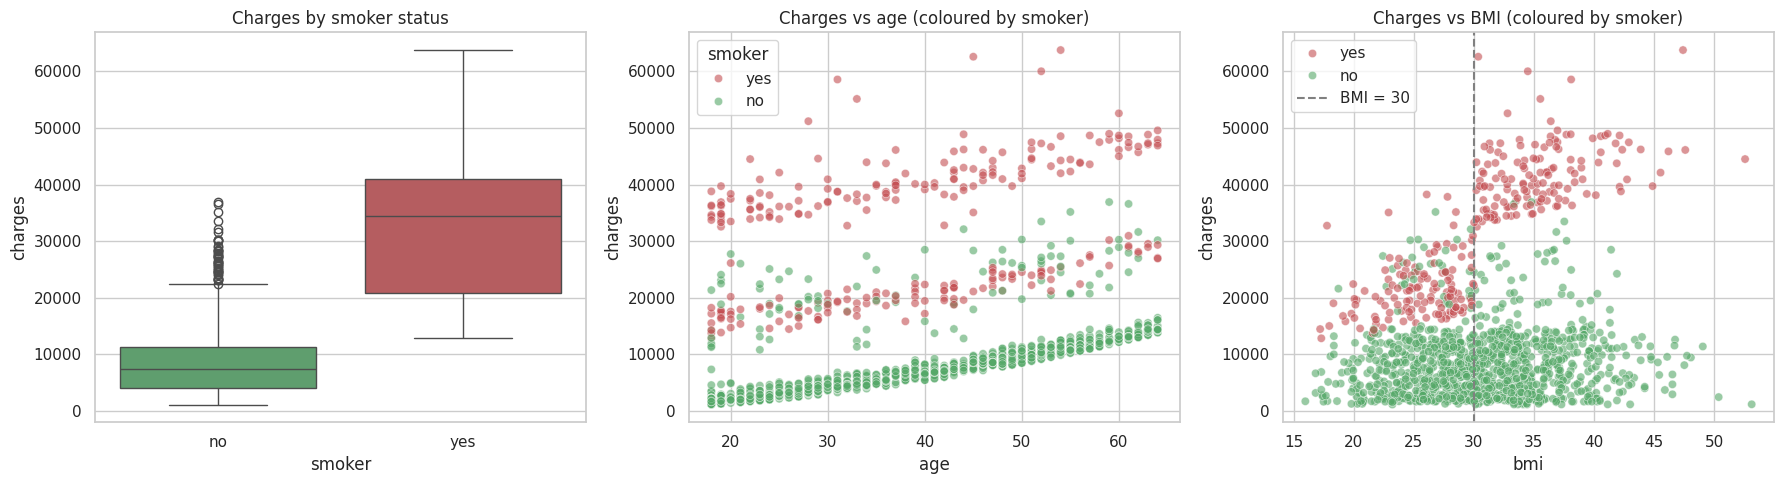

Average charges by smoker status:
           mean   median  count
smoker                         
no       8441.0   7346.0   1063
yes     32050.0  34456.0    274


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x="smoker", y="charges", order=["no", "yes"], hue="smoker", legend=False,
            palette={"no": "#55A868", "yes": "#C44E52"}, ax=axes[0])
axes[0].set_title("Charges by smoker status")

sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.6,
                palette={"no": "#55A868", "yes": "#C44E52"}, ax=axes[1])
axes[1].set_title("Charges vs age (coloured by smoker)")

sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.6,
                palette={"no": "#55A868", "yes": "#C44E52"}, ax=axes[2])
axes[2].axvline(30, color="grey", linestyle="--", label="BMI = 30")
axes[2].legend()
axes[2].set_title("Charges vs BMI (coloured by smoker)")

plt.tight_layout()
plt.show()

print("Average charges by smoker status:")
print(df.groupby("smoker")["charges"].agg(["mean", "median", "count"]).round(0))

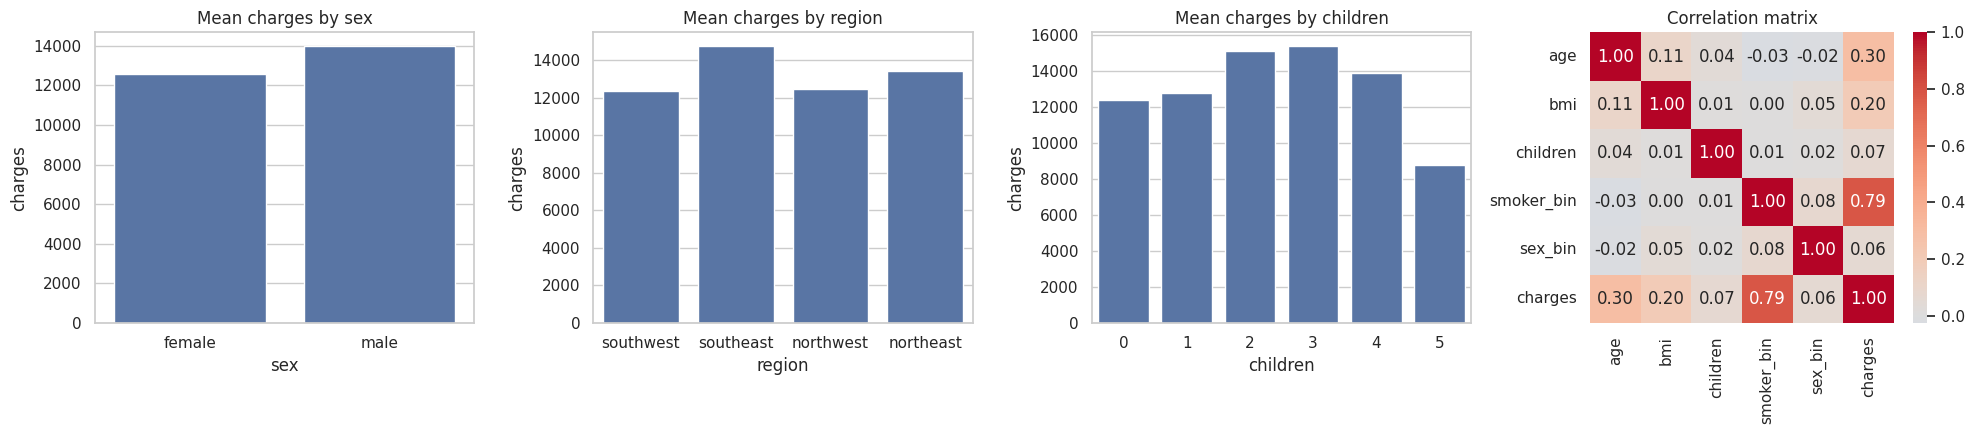

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes[:3], ["sex", "region", "children"]):
    sns.barplot(data=df, x=col, y="charges", ax=ax, color="#4C72B0", errorbar=None)
    ax.set_title(f"Mean charges by {col}")

corr_df = df.assign(smoker_bin=(df["smoker"] == "yes").astype(int),
                    sex_bin=(df["sex"] == "male").astype(int))
corr = corr_df[["age", "bmi", "children", "smoker_bin", "sex_bin", "charges"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[3])
axes[3].set_title("Correlation matrix")
plt.tight_layout()
plt.show()

### What the exploration shows
* **Data quality:** 1,338 rows × 7 columns, **no missing values**, and **1 exact duplicate row**, which I removed (1,337 rows remain). Types are as expected: 3 numeric inputs, 3 categorical inputs and the numeric target.
* **Target is right-skewed** (skewness **1.52**): most people pay between ~$1k and ~$17k, but a long tail goes up to ~$64k. A model trained on raw dollars would be dominated by those few expensive cases. After a log transform the skewness drops to **−0.09**, nearly symmetric.
* **Smoker status is by far the strongest driver.** Smokers (20.5% of people) average **$32,050** against **$8,441** for non-smokers, about 3.8× more, and the two groups barely overlap.
* **Age:** charges rise steadily with age, and the scatter forms bands: a low band (healthy non-smokers), a middle band and a high band (smokers).
* **BMI:** for non-smokers there is almost no relationship with cost. For smokers, costs jump once BMI passes ~30. So BMI matters mostly **in combination with smoking**, which is a hint for a derived feature (an interaction).
* `sex`, `region` and `children` show only small differences in mean charges.

---
# 2. Feature Engineering

### Encoding choices (with justification)
| Column | Method | Why |
|---|---|---|
| `sex` | Label encoding (female = 0, male = 1) | Only two categories, so a single 0/1 column carries all the information. One-hot would just create two perfectly redundant columns. |
| `smoker` | Label encoding (no = 0, yes = 1) | Same reason: binary yes/no, and 0/1 makes the coefficient directly readable as "effect of being a smoker". |
| `region` | One-hot encoding (`drop_first=True`) | Four categories with **no natural order**. Label encoding (0,1,2,3) would falsely tell a linear model that southwest is "more" than northeast. Dropping one dummy (northeast) avoids perfect multicollinearity (the dummy-variable trap) in linear regression. |

### Derived features (my own)
* `bmi_obese`: 1 if BMI ≥ 30, the standard medical threshold for obesity (the EDA showed a jump in cost around that value).
* `smoker_age`: smoker × age. A linear model adds effects, but smoking changes how *age* affects cost, so an interaction term is needed.
* `smoker_obese`: smoker × obese. The table below shows obesity barely matters for non-smokers (~$8.0k → ~$8.9k) but nearly **doubles** cost for smokers (~$21.4k → ~$41.6k).

In [9]:
data = df.copy()

# sex and smoker: binary -> label encoding (0/1)
data["sex"]    = data["sex"].map({"female": 0, "male": 1})
data["smoker"] = data["smoker"].map({"no": 0, "yes": 1})

# region: 4 unordered categories -> one-hot encoding; drop_first avoids the dummy-variable trap
data = pd.get_dummies(data, columns=["region"], drop_first=True, dtype=int)

print("Baseline (dropped) region = northeast")
data.head()

Baseline (dropped) region = northeast


,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


Mean charges by smoker x obesity:


,BMI < 30,BMI >= 30
non-smoker,7977.0,8856.0
smoker,21363.0,41558.0


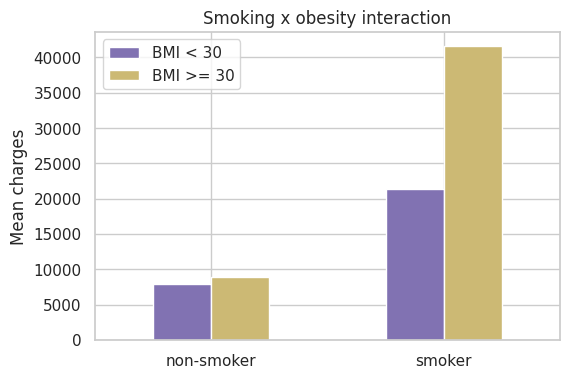

In [10]:
# New feature 1: obesity flag (BMI >= 30 is the standard medical cut-off)
data["bmi_obese"] = (data["bmi"] >= 30).astype(int)

# New feature 2: smoker x age interaction (smoking costs more the older you are)
data["smoker_age"] = data["smoker"] * data["age"]

# New feature 3: smoker x obese interaction (the combination looked especially expensive in the EDA)
data["smoker_obese"] = data["smoker"] * data["bmi_obese"]

# Quick check that the interaction idea is justified by the data
grp = data.groupby(["smoker", "bmi_obese"])["charges"].mean().unstack().round(0)
grp.index = ["non-smoker", "smoker"]
grp.columns = ["BMI < 30", "BMI >= 30"]
print("Mean charges by smoker x obesity:")
display(grp)

grp.plot(kind="bar", figsize=(6, 4), color=["#8172B2", "#CCB974"], rot=0)
plt.ylabel("Mean charges")
plt.title("Smoking x obesity interaction")
plt.show()

### Log transformation of the target
`charges` is strongly right-skewed (skew 1.52). Linear regression works best when the errors are roughly symmetric with similar spread, which a skewed target violates. Taking `log(charges)` pulls in the long tail (skew −0.09), makes relationships more linear, and also means the model predicts *percentage* changes in cost (more natural for prices). Predictions are converted back to dollars with `np.exp()`. All dollar-based metrics below are computed **after** converting back, so they are in real dollars.

### Scaling
Numeric features (`age`, `bmi`, `children`, `smoker_age`) are standardised (mean 0, std 1) with `StandardScaler`. Ordinary least squares does not *need* scaling to fit, but scaling is essential for the polynomial terms (age² and bmi² are on very different scales to the other columns) and it puts coefficients on a comparable footing for interpretation. The 0/1 columns are left as they are. The scaler is placed **inside a Pipeline**, so it is learned from training data only and there is no data leakage.

In [11]:
# charges is strongly right-skewed -> model log(charges) instead
data["log_charges"] = np.log(data["charges"])

print(f"Skew before: {data['charges'].skew():.3f}")
print(f"Skew after:  {data['log_charges'].skew():.3f}")

Skew before: 1.515
Skew after:  -0.090


---
# 3. Model Building
One train/test split (80/20, `random_state=42`, stratified on `smoker`) is created once and reused for **all three models**, so the comparison is fair.

| # | Model | Inputs |
|---|---|---|
| 1 | Simple Linear Regression | The single most predictive feature (selected by correlation on the training set → `smoker`) |
| 2 | Multiple Linear Regression | All 11 engineered features |
| 3 | Polynomial Regression | Polynomial terms (incl. age × bmi interaction) of the numeric features `age` and `bmi`, plus the other features linearly. The degree is picked by cross-validation on the **training** data only, so the test set is never used for tuning. |

In [12]:
feature_cols = [c for c in data.columns if c not in ["charges", "log_charges"]]
X = data[feature_cols]
y = data["log_charges"]        # models are trained on log(charges)

# ONE split, reused by all three models. Stratify on smoker so both sets have the same smoker mix.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=X["smoker"])

print("Features used:", feature_cols)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Smoker share  train: %.3f  test: %.3f" % (X_train["smoker"].mean(), X_test["smoker"].mean()))

# Scale only the continuous columns; binary 0/1 columns are passed through untouched.
# The scaler lives INSIDE each pipeline, so it is fit on training data only (no leakage).
num_cols = ["age", "bmi", "children", "smoker_age"]

def make_scaler():
    return ColumnTransformer([("num", StandardScaler(), num_cols)], remainder="passthrough")

Features used: ['age', 'sex', 'bmi', 'children', 'smoker', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_obese', 'smoker_age', 'smoker_obese']
Train: (1069, 11)  Test: (268, 11)
Smoker share  train: 0.205  test: 0.205


In [13]:
def evaluate(name, model, X_te, y_te_log):
    """Metrics on the test set. R2 (log) is on the model scale; the rest are in real dollars."""
    pred_log = model.predict(X_te)
    actual, pred = np.exp(y_te_log), np.exp(pred_log)
    mse = mean_squared_error(actual, pred)
    return {"Model": name,
            "R2 (log scale)": float(r2_score(y_te_log, pred_log)),
            "R2 ($)": float(r2_score(actual, pred)),
            "MAE ($)": float(mean_absolute_error(actual, pred)),
            "MSE ($^2)": float(mse),
            "RMSE ($)": float(np.sqrt(mse))}

# Pick the single most predictive feature using the training data only
corr_with_target = X_train.corrwith(y_train).sort_values(key=abs, ascending=False)
print("Correlation of each feature with log(charges) [train]:")
print(corr_with_target.round(3))

best_single = corr_with_target.index[0]
print("\nMost predictive single feature:", best_single)

model1 = LinearRegression().fit(X_train[[best_single]], y_train)
print(f"Intercept = {model1.intercept_:.3f}, slope = {model1.coef_[0]:.3f}")
res1 = evaluate("1. Simple Linear (smoker only)", model1, X_test[[best_single]], y_test)
pd.DataFrame([res1]).set_index("Model").round(4)

Correlation of each feature with log(charges) [train]:
smoker              0.658
smoker_age          0.637
smoker_obese        0.574
age                 0.513
children            0.161
bmi                 0.107
bmi_obese           0.102
region_southwest   -0.053
sex                -0.015
region_southeast    0.011
region_northwest    0.001
dtype: float64

Most predictive single feature: smoker
Intercept = 8.799, slope = 1.499


,R2 (log scale),R2 ($),MAE ($),MSE ($^2),RMSE ($)
Model,,,,,
1. Simple Linear (smoker only),0.4828,0.6622,5303.1231,4.869031e+07,6977.844


In [14]:
model2 = Pipeline([("prep", make_scaler()), ("reg", LinearRegression())])
model2.fit(X_train, y_train)
res2 = evaluate("2. Multiple Linear (all features)", model2, X_test, y_test)
pd.DataFrame([res2]).set_index("Model").round(4)

,R2 (log scale),R2 ($),MAE ($),MSE ($^2),RMSE ($)
Model,,,,,
2. Multiple Linear (all features),0.9018,0.8621,2351.3537,1.987410e+07,4458.038


In [15]:
def make_poly_model(degree):
    """Polynomial terms (and their interactions) for the numeric features age and bmi;
    every other feature enters linearly."""
    poly_part = Pipeline([("poly", PolynomialFeatures(degree, include_bias=False)),
                          ("scale", StandardScaler())])
    prep = ColumnTransformer([("poly", poly_part, ["age", "bmi"]),
                              ("num", StandardScaler(), ["children", "smoker_age"])],
                             remainder="passthrough")
    return Pipeline([("prep", prep), ("reg", LinearRegression())])

# Choose the degree with 5-fold CV on the TRAINING set only (test set stays untouched)
rows = []
for d in range(1, 6):
    cv = cross_val_score(make_poly_model(d), X_train, y_train, cv=5, scoring="r2")
    rows.append({"degree": d, "CV R2 (train)": cv.mean()})
degree_table = pd.DataFrame(rows)
display(degree_table)

best_degree = int(degree_table.loc[degree_table["CV R2 (train)"].idxmax(), "degree"])
print("Selected polynomial degree:", best_degree)

model3 = make_poly_model(best_degree).fit(X_train, y_train)
res3 = evaluate(f"3. Polynomial (age, bmi; degree {best_degree})", model3, X_test, y_test)
pd.DataFrame([res3]).set_index("Model").round(4)

,degree,CV R2 (train)
0,1,0.801437
1,2,0.803821
2,3,0.803304
3,4,0.803218
4,5,0.802695


Selected polynomial degree: 2


,R2 (log scale),R2 ($),MAE ($),MSE ($^2),RMSE ($)
Model,,,,,
"3. Polynomial (age, bmi; degree 2)",0.9051,0.8661,2330.4408,19300878.09,4393.2765


---
# 4. Model Evaluation
For every model I report R², MAE, MSE and RMSE on the held-out test set.
* **R² (log scale)** is the score on the scale the model was trained on.
* **R² ($), MAE, MSE, RMSE** are in **real dollars** (predictions converted back with `exp`), which is what a business user cares about.

I also run 5-fold cross-validation on the **whole dataset** (scaler and model refit inside each fold). A single 80/20 split can be lucky or unlucky; CV shows how stable the result is.

Test-set comparison (R2 log = model scale; other metrics in dollars)


,R2 (log scale),R2 ($),MAE ($),MSE ($^2),RMSE ($)
Model,,,,,
1. Simple Linear (smoker only),0.4828,0.6622,5303.12,48690307.0,6977.84
2. Multiple Linear (all features),0.9018,0.8621,2351.35,19874103.0,4458.04
"3. Polynomial (age, bmi; degree 2)",0.9051,0.8661,2330.44,19300878.0,4393.28


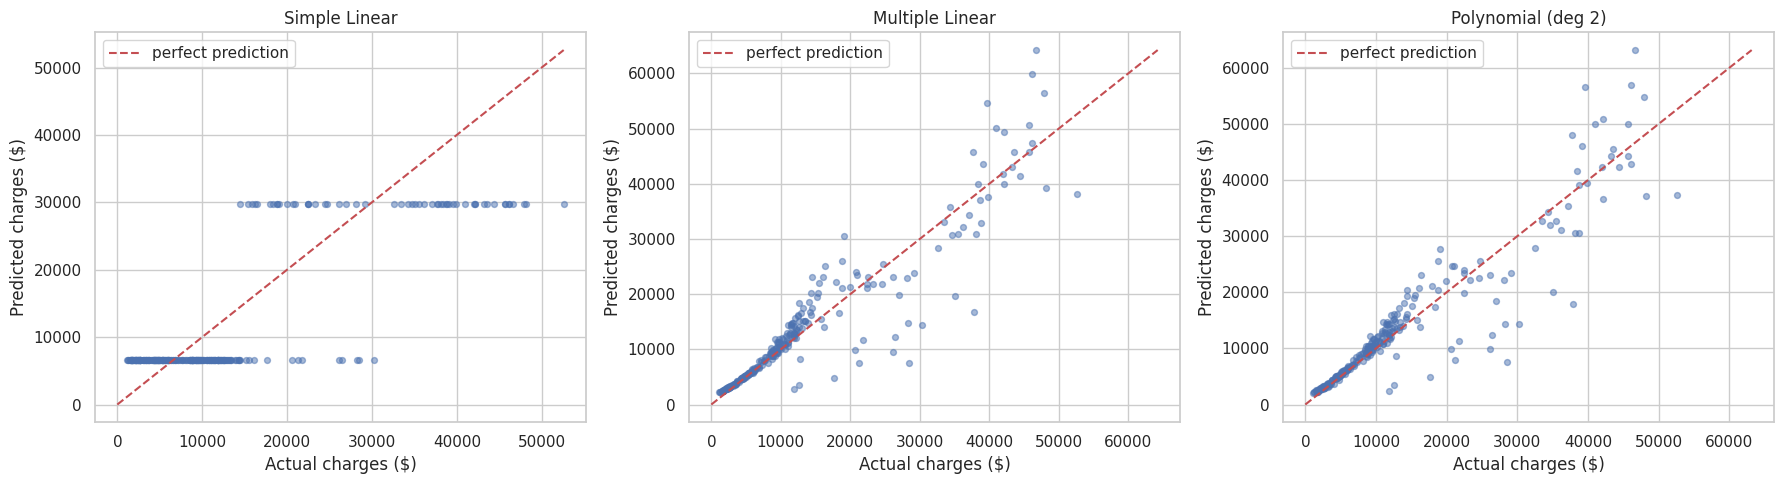

In [16]:
results = pd.DataFrame([res1, res2, res3]).set_index("Model")
print("Test-set comparison (R2 log = model scale; other metrics in dollars)")
display(results.round({"R2 (log scale)": 4, "R2 ($)": 4, "MAE ($)": 2, "MSE ($^2)": 0, "RMSE ($)": 2}))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = [("Simple Linear", model1, X_test[[best_single]]),
          ("Multiple Linear", model2, X_test),
          (f"Polynomial (deg {best_degree})", model3, X_test)]
actual = np.exp(y_test)
for ax, (name, m, Xt) in zip(axes, models):
    pred = np.exp(m.predict(Xt))
    ax.scatter(actual, pred, alpha=0.5, s=18)
    lim = [0, max(actual.max(), pred.max())]
    ax.plot(lim, lim, "r--", label="perfect prediction")
    ax.set_xlabel("Actual charges ($)")
    ax.set_ylabel("Predicted charges ($)")
    ax.set_title(name)
    ax.legend()
plt.tight_layout()
plt.show()

In [17]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, m, cols in [("Simple Linear", LinearRegression(), [best_single]),
                      ("Multiple Linear", Pipeline([("prep", make_scaler()), ("reg", LinearRegression())]), feature_cols),
                      (f"Polynomial (deg {best_degree})", make_poly_model(best_degree), feature_cols)]:
    scores = cross_val_score(m, X[cols], y, cv=kf, scoring="r2")
    cv_rows.append({"Model": name, "Fold scores": np.round(scores, 4).tolist(),
                    "Mean CV R2": scores.mean(), "Std": scores.std()})
cv_table = pd.DataFrame(cv_rows).set_index("Model")
display(cv_table)

,Fold scores,Mean CV R2,Std
Model,,,
Simple Linear,"[0.4992, 0.3944, 0.4362, 0.4145, 0.4577]",0.440388,0.036214
Multiple Linear,"[0.8776, 0.7785, 0.8071, 0.8255, 0.8366]",0.825067,0.032806
Polynomial (deg 2),"[0.8803, 0.7794, 0.8122, 0.8256, 0.8372]",0.826925,0.032976


### Results summary
| Model | R² (log) | R² ($) | MAE ($) | MSE ($²) | RMSE ($) | 5-fold CV R² (log) |
|---|---|---|---|---|---|---|
| 1. Simple Linear (smoker) | 0.4828 | 0.6622 | 5,303 | 48,690,307 | 6,978 | 0.4404 |
| 2. Multiple Linear (11 features) | 0.9018 | 0.8621 | 2,351 | 19,874,103 | 4,458 | 0.8251 |
| 3. Polynomial (age, bmi; degree 2) | 0.9051 | 0.8661 | 2,330 | 19,300,878 | 4,393 | 0.8269 |

* Going from one feature to many is a **huge** improvement (R² 0.48 → 0.90 on the log scale, RMSE ≈ $7.0k → $4.5k).
* Adding polynomial terms on top of the multiple regression gives only a **tiny** extra gain (+0.003 R², about $20 less MAE).
* The cross-validated R² (0.825) is lower than the single-split test R² (0.902). Fold scores range from 0.78 to 0.88, so this particular test split was on the favourable side. **The honest expectation for new data is R² ≈ 0.83 on the log scale**, not 0.90.

---
# 5. Model Selection & Interpretation

### Choice: **Multiple Linear Regression**
Polynomial regression has the highest numbers, so why not choose it? Because the improvement is not meaningful:
1. **The gain is within noise.** CV R² differs by 0.0018 (0.8269 vs 0.8251) while the fold-to-fold standard deviation is ~0.033, roughly 18× larger. Test MAE differs by only ~$20 on an average error of ~$2,300.
2. **It adds complexity for nothing:** three extra terms (age², bmi², age×bmi) with no clear real-world meaning, plus a degree-selection step that itself has to be tuned.
3. **Interpretability.** The multiple linear model's coefficients can be read directly as effects on cost, which matters for insurance pricing, where you need to explain *why* a quote is high.
4. **The simple model is clearly not enough:** R² 0.44 in CV; it ignores age, children and interactions entirely.

Polynomial regression would be the choice only if the extra accuracy mattered more than explainability, and here it does not.

**Known weakness of the chosen model** (see residual plots): errors are larger for smokers (MAE ≈ $5.2k vs ≈ $1.6k for non-smokers). Smokers' costs vary a lot depending on factors not in this dataset (e.g. type of condition), and the residuals fan out slightly at higher predictions. A tree-based model could capture this better, but that is beyond the scope of this assignment.

,feature,coefficient,per_unit_coef,% change in cost per unit
0,smoker,2.4477,2.4477,1056.1970
1,smoker_obese,0.7078,0.7078,102.9601
2,age,0.5728,0.0408,4.1629
3,smoker_age,-0.5512,-0.0332,-3.2615
4,region_southwest,-0.1710,-0.1710,-15.7154
5,region_southeast,-0.1389,-0.1389,-12.9648
6,children,0.1357,0.1149,12.1753
7,sex,-0.1002,-0.1002,-9.5357
8,region_northwest,-0.0569,-0.0569,-5.5266
9,bmi_obese,-0.0370,-0.0370,-3.6350


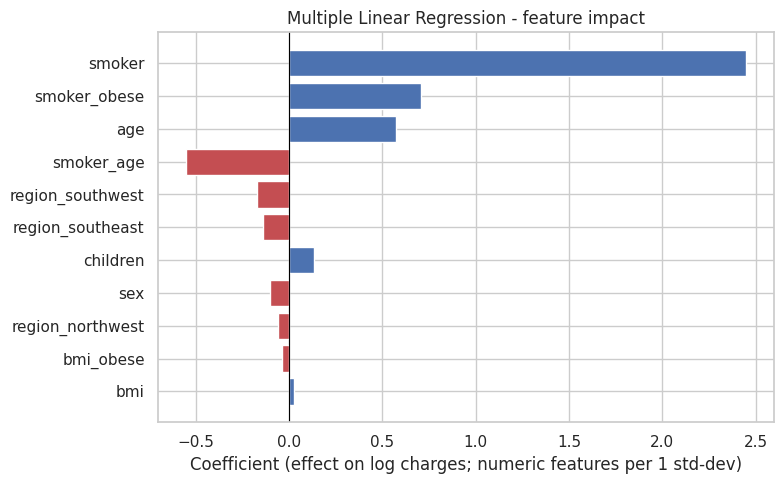

Smoker effect at age 20, not obese: cost x 5.96  (+496%)
Smoker effect at age 20, obese: cost x 12.09  (+1109%)
Smoker effect at age 40, not obese: cost x 3.07  (+207%)
Smoker effect at age 40, obese: cost x 6.23  (+523%)
Smoker effect at age 60, not obese: cost x 1.58  (+58%)
Smoker effect at age 60, obese: cost x 3.21  (+221%)


In [18]:
final_model = model2     # Multiple Linear Regression (justified in the markdown above)

prep = final_model.named_steps["prep"]
names = [n.split("__")[1] for n in prep.get_feature_names_out()]
coef = final_model.named_steps["reg"].coef_
scale = dict(zip(num_cols, prep.named_transformers_["num"].scale_))

coef_df = pd.DataFrame({"feature": names, "coefficient": coef})
# Coefficients of scaled columns are "per 1 std-dev"; convert to "per 1 unit" to get % change in cost
coef_df["per_unit_coef"] = coef_df["coefficient"] / coef_df["feature"].map(scale).fillna(1.0)
coef_df["% change in cost per unit"] = (np.exp(coef_df["per_unit_coef"]) - 1) * 100
coef_df = coef_df.reindex(coef_df["coefficient"].abs().sort_values(ascending=False).index)
display(coef_df.round(4).reset_index(drop=True))

plt.figure(figsize=(8, 5))
colors = ["#C44E52" if c < 0 else "#4C72B0" for c in coef_df["coefficient"]]
plt.barh(coef_df["feature"], coef_df["coefficient"], color=colors)
plt.gca().invert_yaxis()
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Coefficient (effect on log charges; numeric features per 1 std-dev)")
plt.title("Multiple Linear Regression - feature impact")
plt.tight_layout()
plt.show()

# Smoker main effect alone is misleading because of the interactions; compute the TOTAL smoker effect
raw = dict(zip(coef_df["feature"], coef_df["per_unit_coef"]))
for age in [20, 40, 60]:
    for obese in [0, 1]:
        eff = raw["smoker"] + raw["smoker_age"] * age + raw["smoker_obese"] * obese
        print(f"Smoker effect at age {age}, {'obese' if obese else 'not obese'}: "
              f"cost x {np.exp(eff):.2f}  (+{(np.exp(eff)-1)*100:.0f}%)")

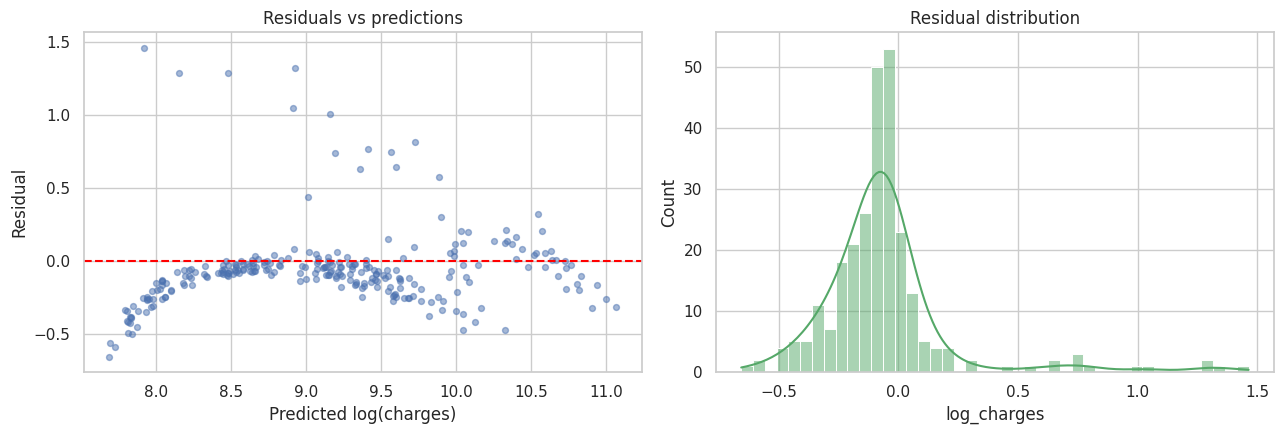

Mean absolute error ($) by group:
smoker
non-smoker    1622.0
smoker        5177.0
Name: abs_error, dtype: float64


In [19]:
pred_log = final_model.predict(X_test)
residuals = y_test - pred_log

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(pred_log, residuals, alpha=0.5, s=18)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted log(charges)")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs predictions")
sns.histplot(residuals, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

# Where does the model struggle? Error split by smoker group
actual, pred = np.exp(y_test), np.exp(pred_log)
err = pd.DataFrame({"smoker": X_test["smoker"].map({0: "non-smoker", 1: "smoker"}),
                    "abs_error": (actual - pred).abs()})
print("Mean absolute error ($) by group:")
print(err.groupby("smoker")["abs_error"].mean().round(0))

### Interpretation of the coefficients
The coefficients act on `log(charges)`, so `exp(coef) − 1` is a percentage change in cost. Numeric features are standardised, so their coefficients are "per 1 std-dev", and the table also shows the converted per-unit effect.

**Biggest impacts (in order):**
1. **Smoking: dominant, as expected from the EDA.** Because of the interaction terms, "smoker" must be read together with `smoker_age` and `smoker_obese`. The combined effect, printed above, is: cost is ×6.0 higher for a non-obese 20-year-old smoker, ×3.1 at age 40 and ×1.6 at age 60. For an obese smoker the multiplier roughly doubles (×12.1 at 20, ×6.2 at 40, ×3.2 at 60). The negative `smoker_age` coefficient means the *relative* penalty shrinks with age (because non-smokers' costs grow with age while the smoker premium is roughly a fixed dollar amount).
2. **Obesity × smoking** (`smoker_obese`, +103% on its own): confirms the interaction spotted in the EDA. Obesity alone is not costly; obesity *in smokers* is.
3. **Age:** about **+4.2% per extra year** for non-smokers, the most important non-smoking factor.
4. **Children:** about **+12% per child**.
5. **Region and sex:** small effects. Southwest and southeast are ~13–16% cheaper than the baseline northeast; men are ~10% cheaper once smoking is controlled for (men smoke more, so the raw averages hide this).
6. **BMI itself** is small (+0.4% per BMI point); its real influence works through the obese-smoker interaction.

**Does this match expectations from the exploration?** Yes for the main story: smoking ≫ age > everything else, and BMI matters only for smokers. Two things were less obvious: (a) the strength of the smoker × age *interaction* (the smoker premium falls with age), and (b) the sex effect turning slightly negative after controlling for smoking.

**Caution:** `smoker`, `smoker_age`, `smoker_obese` (and `bmi` / `bmi_obese`) are strongly correlated with each other by construction. Individual coefficients such as the slightly negative `bmi_obese` should therefore not be over-interpreted; read each correlated group *together*, as done above. Prediction accuracy is not affected by this.

---
# 6. Lightweight Model Deployment
Steps:
1. Refit the chosen pipeline (scaler + linear regression) on **all** the data. The test-set metrics above were measured on the train-only version; with the model type already validated, using all data gives the final model a bit more to learn from.
2. Save it with `joblib`, together with the list of feature columns, so a new person's features can be rebuilt in exactly the same order.
3. `predict_insurance_cost(age, sex, bmi, children, smoker, region)` loads the file, rebuilds the engineered features (encoding, obesity flag, interactions), predicts `log(charges)` and converts it back to dollars with `exp`. No retraining is needed.

In [20]:
# Refit the final model on ALL data, then save it together with the info needed to rebuild features
final_deploy_model = Pipeline([("prep", make_scaler()), ("reg", LinearRegression())])
final_deploy_model.fit(X, y)

bundle = {"model": final_deploy_model,
          "feature_columns": feature_cols,
          "region_columns": [c for c in feature_cols if c.startswith("region_")],
          "target_transform": "log  ->  predictions must be passed through np.exp()"}
joblib.dump(bundle, "insurance_model.joblib")

import os
print("Saved insurance_model.joblib  (%.1f KB)" % (os.path.getsize("insurance_model.joblib") / 1024))

Saved insurance_model.joblib  (3.3 KB)


In [21]:
def predict_insurance_cost(age, sex, bmi, children, smoker, region,
                           model_path="insurance_model.joblib"):
    """Load the saved model and return the predicted yearly insurance charge ($) for one person.
    sex: 'male'/'female' | smoker: 'yes'/'no' | region: northeast/northwest/southeast/southwest"""
    sex, smoker, region = str(sex).lower(), str(smoker).lower(), str(region).lower()
    if sex not in ("male", "female"):                 raise ValueError("sex must be 'male' or 'female'")
    if smoker not in ("yes", "no"):                   raise ValueError("smoker must be 'yes' or 'no'")
    if region not in ("northeast", "northwest", "southeast", "southwest"):
        raise ValueError("region must be northeast, northwest, southeast or southwest")

    bundle = joblib.load(model_path)

    # Rebuild exactly the same features used in training
    smoker_n = 1 if smoker == "yes" else 0
    obese = int(bmi >= 30)
    row = {"age": age, "sex": 1 if sex == "male" else 0, "bmi": bmi, "children": children,
           "smoker": smoker_n, "bmi_obese": obese,
           "smoker_age": smoker_n * age, "smoker_obese": smoker_n * obese}
    for col in bundle["region_columns"]:               # region_northwest, region_southeast, region_southwest
        row[col] = int(col == f"region_{region}")

    X_new = pd.DataFrame([row])[bundle["feature_columns"]]
    return float(np.exp(bundle["model"].predict(X_new))[0])   # undo the log transform


# --- Tests -------------------------------------------------------------------------------------
examples = [
    dict(age=25, sex="female", bmi=22.5, children=0, smoker="no",  region="southwest"),
    dict(age=25, sex="female", bmi=22.5, children=0, smoker="yes", region="southwest"),   # same person, smoker
    dict(age=45, sex="male",   bmi=33.0, children=2, smoker="yes", region="southeast"),
    dict(age=60, sex="female", bmi=27.0, children=1, smoker="no",  region="northeast"),
]
for ex in examples:
    print(f"{ex}\n   -> predicted cost: ${predict_insurance_cost(**ex):,.2f}\n")

# Sanity check: a fresh load of the file reproduces the in-memory model
sample = X.iloc[[0]]
in_memory = float(np.exp(final_deploy_model.predict(sample))[0])
r0 = df.iloc[0]
from_file = predict_insurance_cost(r0.age, r0.sex, r0.bmi, r0.children, r0.smoker, r0.region)
print("Sanity check -> in-memory: %.2f | from saved file: %.2f | actual charge: %.2f" % (in_memory, from_file, r0.charges))

{'age': 25, 'sex': 'female', 'bmi': 22.5, 'children': 0, 'smoker': 'no', 'region': 'southwest'}
   -> predicted cost: $3,075.09

{'age': 25, 'sex': 'female', 'bmi': 22.5, 'children': 0, 'smoker': 'yes', 'region': 'southwest'}
   -> predicted cost: $15,818.90

{'age': 45, 'sex': 'male', 'bmi': 33.0, 'children': 2, 'smoker': 'yes', 'region': 'southeast'}
   -> predicted cost: $43,945.31

{'age': 60, 'sex': 'female', 'bmi': 27.0, 'children': 1, 'smoker': 'no', 'region': 'northeast'}
   -> predicted cost: $17,403.78

Sanity check -> in-memory: 15501.84 | from saved file: 15501.84 | actual charge: 16884.92


In [22]:
# In Colab: download the saved model so you can submit it with the notebook (does nothing elsewhere)
try:
    from google.colab import files
    files.download("insurance_model.joblib")
except ImportError:
    print("Not running in Colab - the model file is in the current folder.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Conclusion
* A full regression workflow was built on the insurance data: EDA → feature engineering → 3 models → multi-metric evaluation + cross-validation → interpretation → saved, reusable model.
* **Final model:** Multiple Linear Regression on `log(charges)` with 11 features, test R² 0.90 (log) / 0.86 ($), RMSE ≈ $4.5k, cross-validated R² ≈ 0.83.
* **Key findings:** smoking status (especially combined with obesity) is the dominant cost driver, followed by age and number of children. Polynomial terms add almost nothing.
* **Limitations / next steps:** larger errors for smokers; the log back-transform predicts a typical (median-like) cost and slightly under-predicts averages; tree-based models (Random Forest, Gradient Boosting) and regularised regression could be tried to reduce the smoker error.